# Customer Churn Prediction Using Machine Learning

## Project Objective

The objective of this project is to predict whether a telecom customer is likely to leave the service using customer account information, service usage, and machine learning classification algorithms.

## Algorithms

1. Logistic Regression
2. Decision Tree Classifier

## Tools and Technologies

* Python
* Pandas and NumPy
* Matplotlib and Seaborn
* Scikit-learn

## Evaluation Metrics

* Accuracy
* Precision
* Recall
* F1-score
* Confusion Matrix


In [1]:



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
file_path = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Column Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nNumerical Summary:")
display(df.describe())

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


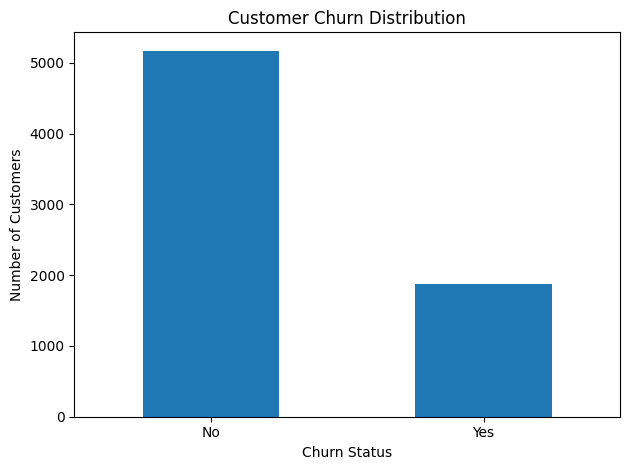

In [4]:
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))


df["Churn"].value_counts().plot(
    kind="bar",
    title="Customer Churn Distribution",
    xlabel="Churn Status",
    ylabel="Number of Customers",
    rot=0
)

plt.tight_layout()
plt.show()

In [5]:
print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (7043, 21)

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract       

In [6]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("Missing TotalCharges after conversion:",
      df["TotalCharges"].isnull().sum())

print("\nRows with missing TotalCharges:")
display(df[df["TotalCharges"].isnull()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
])

Missing TotalCharges after conversion: 11

Rows with missing TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [7]:
df = df.dropna(subset=["TotalCharges"]).copy()

print("Cleaned dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Cleaned dataset shape: (7032, 21)
Remaining missing values: 0


Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


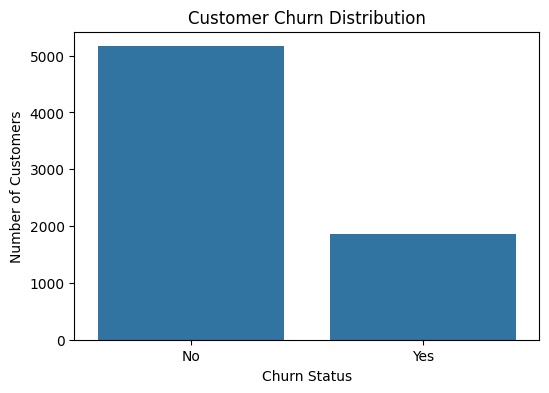

In [8]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)
print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.72  11.28
Two year        97.15   2.85


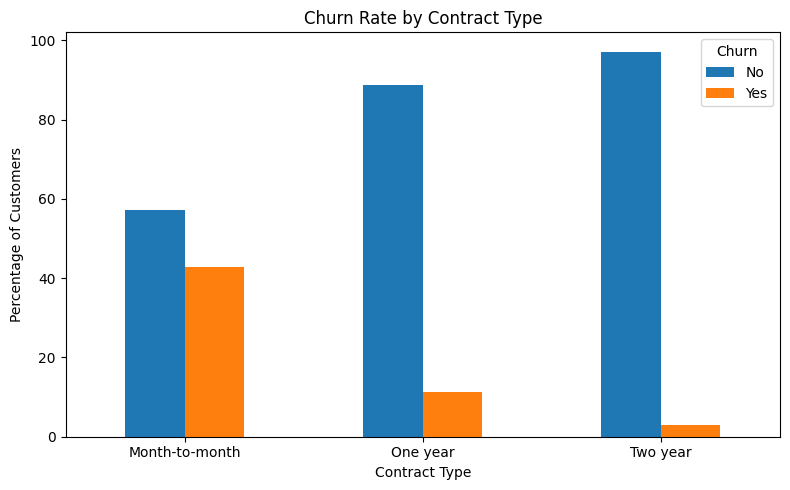

In [9]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

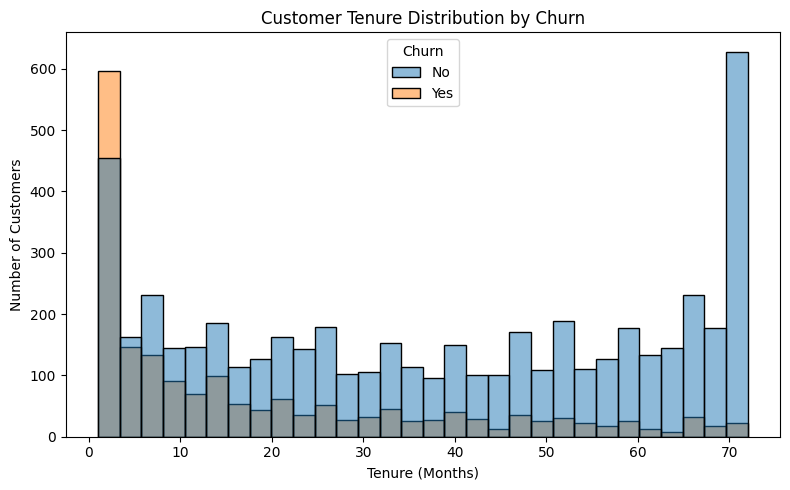

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="layer",
    kde=False
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

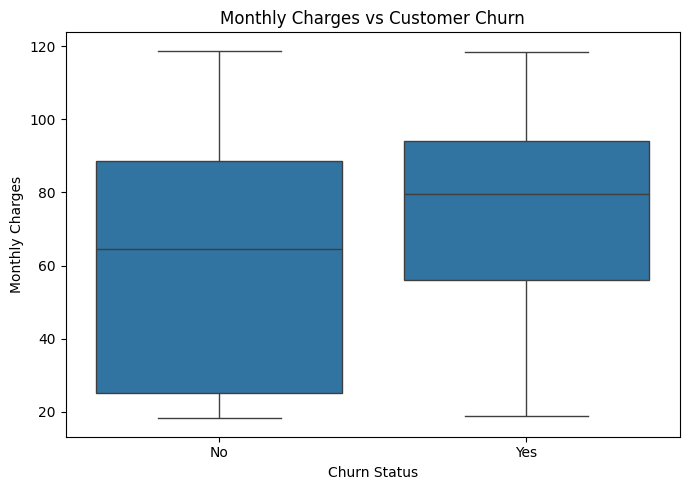

In [11]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

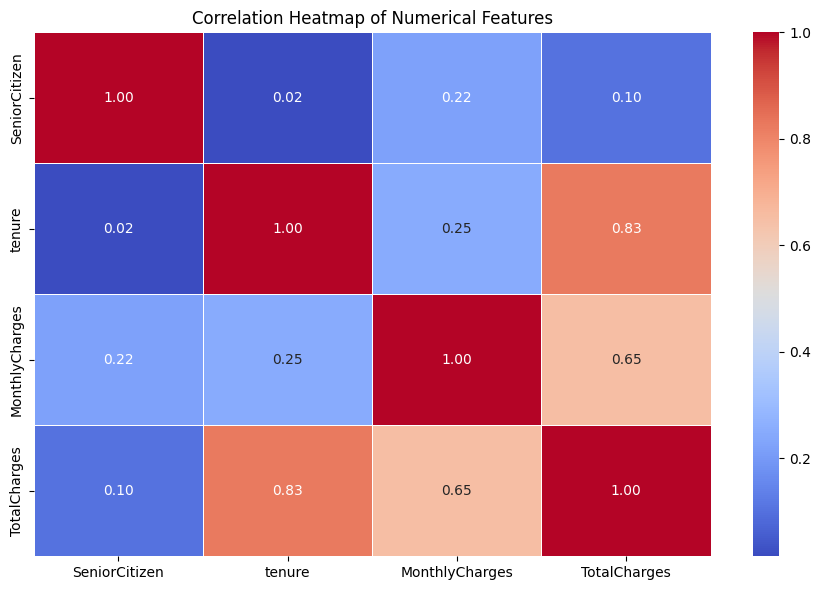

In [12]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [13]:
print("Final dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())
print("Target column:", "Churn")
print("Target classes:", df["Churn"].unique())

display(df.head())

Final dataset shape: (7032, 21)
Duplicate rows: 0
Missing values: 0
Target column: Churn
Target classes: ['No' 'Yes']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:
X = df.drop(columns=["customerID", "Churn"])


y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7032, 19)
Target shape: (7032,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [15]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5625, 19)
Testing features: (1407, 19)

Training target distribution:
Churn
No     0.734
Yes    0.266
Name: proportion, dtype: float64

Testing target distribution:
Churn
No     0.734
Yes    0.266
Name: proportion, dtype: float64


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Original training shape: (5625, 19)
Processed training shape: (5625, 45)

Original testing shape: (1407, 19)
Processed testing shape: (1407, 45)

Preprocessing completed successfully!


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])


logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [20]:
y_pred_lr = logistic_model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10].tolist())

print("\nPredictions generated successfully!")

First 10 actual values:
['No', 'No', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'Yes', 'No']

First 10 predicted values:
['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No']

Predictions generated successfully!


In [21]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=20,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [22]:
y_pred_dt = decision_tree_model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_dt[:10].tolist())

print("\nDecision Tree predictions generated successfully!")

First 10 actual values:
['No', 'No', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'Yes', 'No']

First 10 predicted values:
['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No']

Decision Tree predictions generated successfully!


In [23]:
from sklearn.metrics import accuracy_score

accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Logistic Regression Accuracy: {accuracy_lr:.4f}")
print(f"Decision Tree Accuracy:       {accuracy_dt:.4f}")

Logistic Regression Accuracy: 0.8038
Decision Tree Accuracy:       0.7896


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_model(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label="Yes"
        ),
        "F1-Score": f1_score(
            y_true, y_pred, pos_label="Yes"
        )
    }

lr_results = evaluate_model(
    y_test, y_pred_lr, "Logistic Regression"
)

dt_results = evaluate_model(
    y_test, y_pred_dt, "Decision Tree"
)

print("Evaluation metrics calculated successfully!")

Evaluation metrics calculated successfully!


In [25]:
results_df = pd.DataFrame([
    lr_results,
    dt_results
])

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,80.38%,64.85%,57.22%,60.80%
1,Decision Tree,78.96%,60.21%,61.50%,60.85%


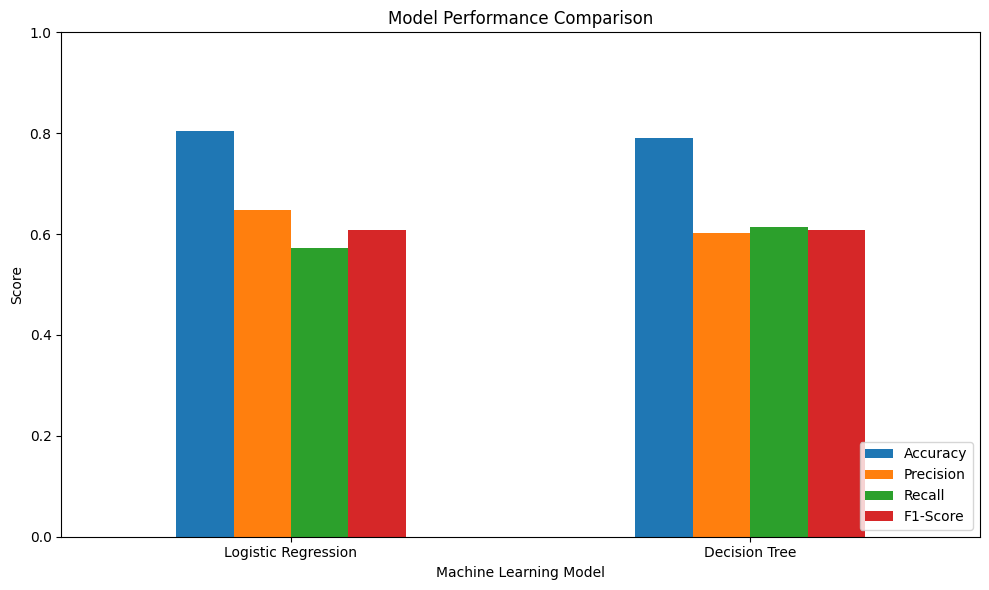

In [26]:

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison = results_df.set_index("Model")[metrics]

comparison.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

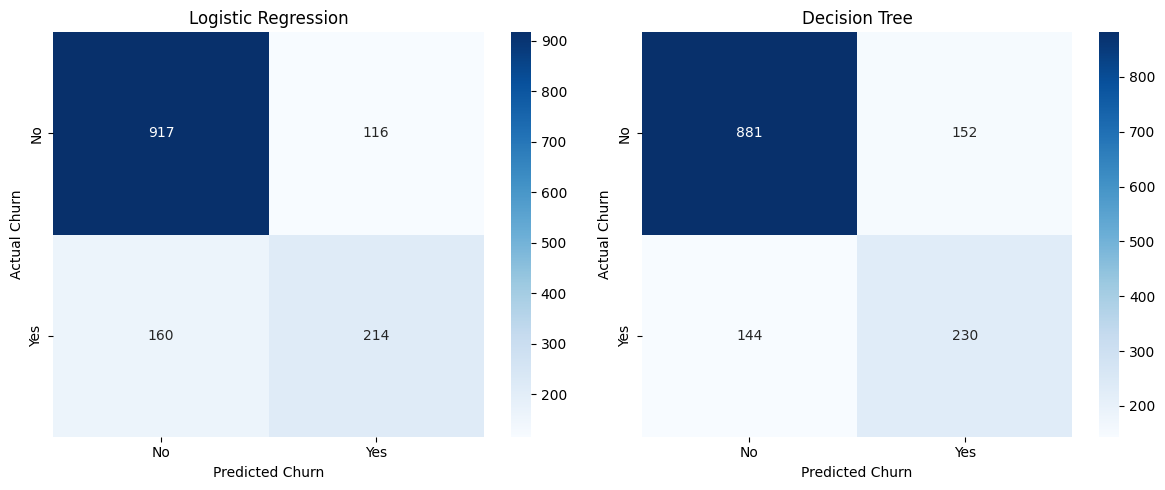

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in [
    (axes[0], y_pred_lr, "Logistic Regression"),
    (axes[1], y_pred_dt, "Decision Tree")
]:
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["No", "Yes"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Churn")
    ax.set_ylabel("Actual Churn")

plt.tight_layout()
plt.show()

In [29]:
print("LOGISTIC REGRESSION REPORT")
print(classification_report(
    y_test,
    y_pred_lr,
    labels=["No", "Yes"],
    zero_division=0
))

print("\nDECISION TREE REPORT")
print(classification_report(
    y_test,
    y_pred_dt,
    labels=["No", "Yes"],
    zero_division=0
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


DECISION TREE REPORT
              precision    recall  f1-score   support

          No       0.86      0.85      0.86      1033
         Yes       0.60      0.61      0.61       374

    accuracy                           0.79      1407
   macro avg       0.73      0.73      0.73      1407
weighted avg       0.79      0.79      0.79      1407



In [30]:
if lr_results["F1-Score"] >= dt_results["F1-Score"]:
    best_model = logistic_model
    best_model_name = "Logistic Regression"
    best_predictions = y_pred_lr
else:
    best_model = decision_tree_model
    best_model_name = "Decision Tree"
    best_predictions = y_pred_dt

print("Selected model:", best_model_name)
print(
    "Churn F1-score:",
    round(max(lr_results["F1-Score"], dt_results["F1-Score"]), 4)
)

Selected model: Decision Tree
Churn F1-score: 0.6085


In [31]:
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.50,
    "TotalCharges": 171.00
}])

display(new_customer)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,85.5,171.0


In [32]:
prediction = best_model.predict(new_customer)[0]

print("Selected model:", best_model_name)
print("Predicted churn status:", prediction)

if prediction == "Yes":
    print("Result: The model predicts that the customer may churn.")
else:
    print("Result: The model predicts that the customer may stay.")

Selected model: Decision Tree
Predicted churn status: Yes
Result: The model predicts that the customer may churn.


In [33]:
probabilities = best_model.predict_proba(new_customer)[0]

class_labels = best_model.named_steps["classifier"].classes_
churn_index = list(class_labels).index("Yes")

churn_probability = probabilities[churn_index] * 100
stay_probability = 100 - churn_probability

print(f"Probability of churn: {churn_probability:.2f}%")
print(f"Probability of staying: {stay_probability:.2f}%")

Probability of churn: 75.51%
Probability of staying: 24.49%


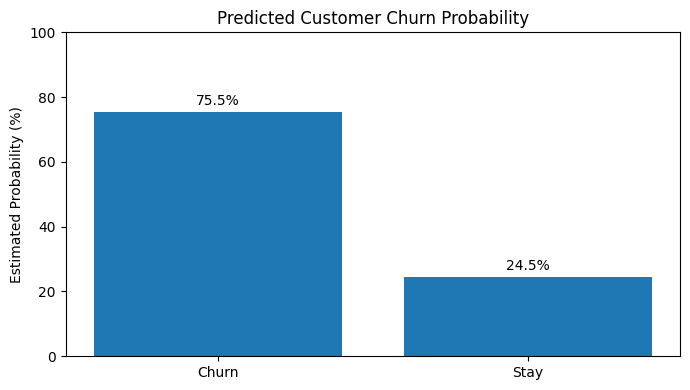

In [34]:
labels = ["Churn", "Stay"]
values = [churn_probability, stay_probability]

plt.figure(figsize=(7, 4))

bars = plt.bar(labels, values)

plt.title("Predicted Customer Churn Probability")
plt.ylabel("Estimated Probability (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [35]:
customer_2 = new_customer.copy()

customer_2["tenure"] = 24
customer_2["Contract"] = "One year"
customer_2["TotalCharges"] = (
    customer_2["MonthlyCharges"] * customer_2["tenure"]
)

prediction_2 = best_model.predict(customer_2)[0]

probabilities_2 = best_model.predict_proba(customer_2)[0]
churn_probability_2 = probabilities_2[
    list(class_labels).index("Yes")
] * 100

comparison_customers = pd.DataFrame({
    "Customer": ["Customer 1", "Customer 2"],
    "Tenure (months)": [
        int(new_customer["tenure"].iloc[0]),
        int(customer_2["tenure"].iloc[0])
    ],
    "Contract": [
        new_customer["Contract"].iloc[0],
        customer_2["Contract"].iloc[0]
    ],
    "Predicted Churn": [prediction, prediction_2],
    "Churn Probability (%)": [
        churn_probability,
        churn_probability_2
    ]
})

display(comparison_customers.round(2))

,Customer,Tenure (months),Contract,Predicted Churn,Churn Probability (%)
0,Customer 1,2,Month-to-month,Yes,75.51
1,Customer 2,24,One year,No,11.65


In [36]:



print("Selected model:", best_model_name)
print("Model:", best_model)
print("Training rows:", len(X_train))
print("Target classes:", sorted(y_train.unique()))

Selected model: Decision Tree
Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('

In [37]:
import joblib
from google.colab import files


model_filename = "customer_churn_model.pkl"
joblib.dump(best_model, model_filename)

print("Model saved successfully!")
print("Selected model:", best_model_name)
print("Saved file:", model_filename)


files.download(model_filename)

Model saved successfully!
Selected model: Decision Tree
Saved file: customer_churn_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:

!pip install -q streamlit joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 54.9 MB/s eta 0:00:00


In [39]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib


model = joblib.load("customer_churn_model.pkl")

st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Customer Churn Prediction")
st.write(
    "Predict whether a telecom customer is likely to leave "
    "the service using a Machine Learning model."
)

st.divider()

st.subheader("Enter Customer Details")

col1, col2, col3 = st.columns(3)

with col1:
    gender = st.selectbox("Gender", ["Female", "Male"])
    senior = st.selectbox("Senior Citizen", ["No", "Yes"])
    partner = st.selectbox("Has Partner?", ["Yes", "No"])
    dependents = st.selectbox("Has Dependents?", ["Yes", "No"])
    tenure = st.slider("Tenure (months)", 0, 72, 12)
    phone = st.selectbox("Phone Service", ["Yes", "No"])
    multiple_lines = st.selectbox(
        "Multiple Lines", ["No", "Yes", "No phone service"]
    )

with col2:
    internet = st.selectbox(
        "Internet Service", ["DSL", "Fiber optic", "No"]
    )
    security = st.selectbox(
        "Online Security", ["Yes", "No", "No internet service"]
    )
    backup = st.selectbox(
        "Online Backup", ["Yes", "No", "No internet service"]
    )
    protection = st.selectbox(
        "Device Protection", ["Yes", "No", "No internet service"]
    )
    support = st.selectbox(
        "Tech Support", ["Yes", "No", "No internet service"]
    )
    streaming_tv = st.selectbox(
        "Streaming TV", ["Yes", "No", "No internet service"]
    )
    streaming_movies = st.selectbox(
        "Streaming Movies", ["Yes", "No", "No internet service"]
    )

with col3:
    contract = st.selectbox(
        "Contract",
        ["Month-to-month", "One year", "Two year"]
    )
    paperless = st.selectbox("Paperless Billing", ["Yes", "No"])
    payment = st.selectbox(
        "Payment Method",
        [
            "Electronic check",
            "Mailed check",
            "Bank transfer (automatic)",
            "Credit card (automatic)"
        ]
    )
    monthly_charges = st.number_input(
        "Monthly Charges ($)", min_value=0.0,
        max_value=1000.0, value=70.0, step=1.0
    )
    total_charges = st.number_input(
        "Total Charges ($)", min_value=0.0,
        max_value=100000.0,
        value=float(monthly_charges * tenure),
        step=10.0
    )

st.caption(
    "Use realistic customer details. Charges and tenure should "
    "be consistent with the customer's account."
)

if st.button("🔍 Predict Churn", type="primary", use_container_width=True):
    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": 1 if senior == "Yes" else 0,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone,
        "MultipleLines": multiple_lines,
        "InternetService": internet,
        "OnlineSecurity": security,
        "OnlineBackup": backup,
        "DeviceProtection": protection,
        "TechSupport": support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless,
        "PaymentMethod": payment,
        "MonthlyCharges": monthly_charges,
        "TotalCharges": total_charges
    }])

    prediction = model.predict(customer)[0]
    probabilities = model.predict_proba(customer)[0]
    classes = list(model.named_steps["classifier"].classes_)
    churn_probability = float(
        probabilities[classes.index("Yes")] * 100
    )

    st.divider()
    st.subheader("Prediction Result")

    result_col1, result_col2 = st.columns(2)

    with result_col1:
        if prediction == "Yes":
            st.error("⚠️ Customer is predicted to churn")
        else:
            st.success("✅ Customer is predicted to stay")

    with result_col2:
        st.metric("Estimated Churn Probability", f"{churn_probability:.1f}%")
        st.progress(int(round(churn_probability)))

    st.info(
        "This is a model estimate, not a guarantee of customer behavior."
    )

st.divider()
st.caption("Customer Churn Prediction | Machine Learning Portfolio Project")

Writing app.py


In [40]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("Model file exists:", os.path.exists("customer_churn_model.pkl"))

app.py exists: True
Model file exists: True


In [41]:

!pip install -q pyngrok

In [42]:
import subprocess
import time


process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(5)

print("Streamlit process running:", process.poll() is None)

Streamlit process running: True


In [44]:
from pyngrok import ngrok

ngrok.set_auth_token("3KUPsj9MxtQ60TBW8LojcqmaMVf_7uhymFMCnnsPPX8d3QGX3")

public_url = ngrok.connect(8501)
print("Open your Customer Churn webpage here:")
print(public_url)

Open your Customer Churn webpage here:
NgrokTunnel: "https://parchment-cottage-glade.ngrok-free.dev" -> "http://localhost:8501"
